## Set up Code

Shape: (2728, 1528)
Data Type: uint8
Min: 0, Max: 255


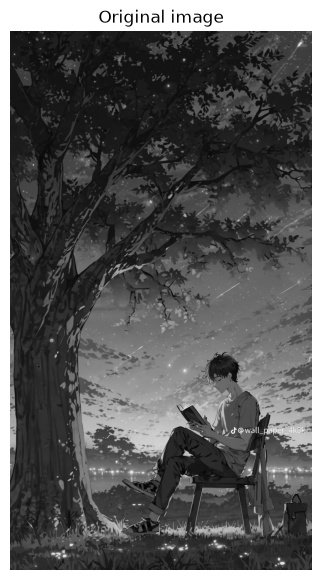

In [10]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img=cv.imread('image.jpg',cv.IMREAD_GRAYSCALE)

if img is None:
    print("Error Image is not found.Check the file path")
else:
    print(f"Shape: {img.shape}")
    print(f"Data Type: {img.dtype}")
    print(f"Min: {img.min()}, Max: {img.max()}")

#Display original image
plt.figure(figsize=(7,7))
plt.imshow(img,cmap='gray',vmin=0,vmax=255)
plt.title("Original image")
plt.axis('off')
plt.show()


## Brightness Adjustment

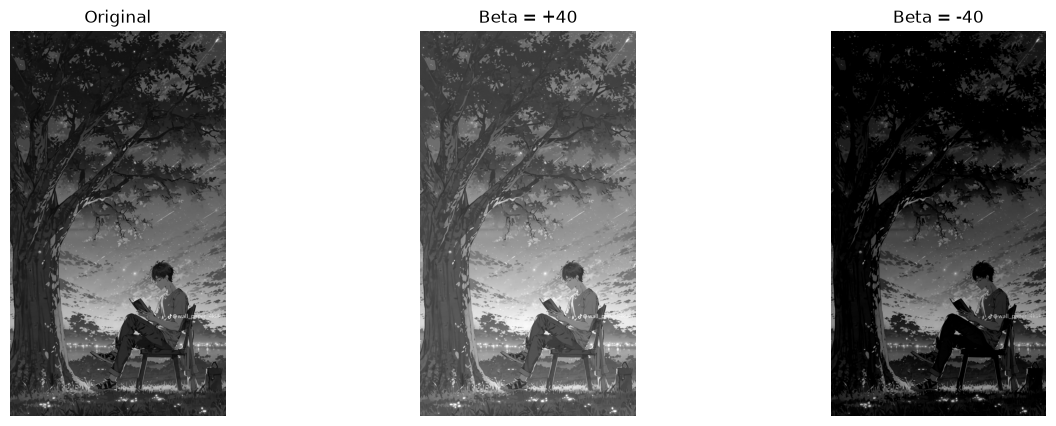

In [11]:


def adjust_brightness(image, beta):
    # Convert to int16 (wider type) to prevent overflow/underflow during addition
    
    temp = image.astype(np.int16) + beta  
    
    # Clip values to 0-255.
    temp = np.clip(temp, 0, 255)         
    
    # Truncate back to uint8 for display
    return temp.astype(np.uint8)         

# Apply brightness
bright_plus = adjust_brightness(img, 40)
bright_minus = adjust_brightness(img, -40)

# Display results
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(img, cmap='gray', vmin=0, vmax=255); axs[0].set_title("Original")
axs[1].imshow(bright_plus, cmap='gray', vmin=0, vmax=255); axs[1].set_title("Beta = +40")
axs[2].imshow(bright_minus, cmap='gray', vmin=0, vmax=255); axs[2].set_title("Beta = -40")
for ax in axs: ax.axis('off')
plt.show()

## Linear Constarst

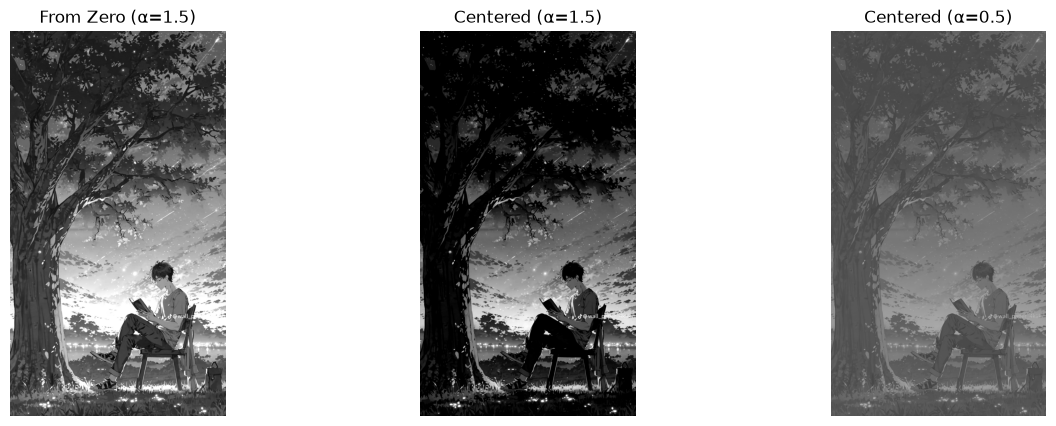

In [12]:

def contrast_from_zero(image, alpha):
    temp = image.astype(np.float32) * alpha
    temp = np.clip(temp, 0, 255)
    return temp.astype(np.uint8) # Truncates decimals


def contrast_centered(image, alpha):
    temp = (image.astype(np.float32) - 128) * alpha + 128
    temp = np.clip(temp, 0, 255)
    return temp.astype(np.uint8)
    
c_zero_15 = contrast_from_zero(img, 1.5)
c_center_15 = contrast_centered(img, 1.5)
c_center_05 = contrast_centered(img, 0.5)

# Display
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(c_zero_15, cmap='gray', vmin=0, vmax=255); axs[0].set_title("From Zero (α=1.5)")
axs[1].imshow(c_center_15, cmap='gray', vmin=0, vmax=255); axs[1].set_title("Centered (α=1.5)")
axs[2].imshow(c_center_05, cmap='gray', vmin=0, vmax=255); axs[2].set_title("Centered (α=0.5)")
for ax in axs: ax.axis('off')
plt.show()

## Image Negative

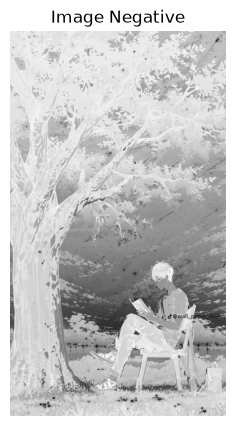

In [13]:
neg_img=255-img

plt.figure(figsize=(5,5))
plt.imshow(neg_img,cmap='gray',vmin=0,vmax=255)
plt.title("Image Negative")
plt.axis('off')
plt.show()

## Gamma Correction

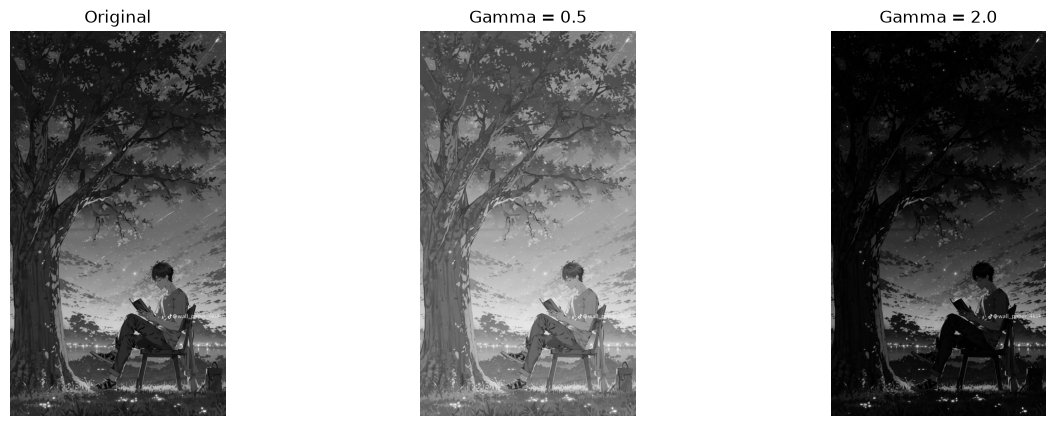

In [ ]:
def gamma_correction(image,gamma):
    norm=image.astype(np.float32)/255.0
    powered=np.power(norm,gamma)
    temp=np.clip(powered*255.0,0,2 55)
    return temp.astype(np.uint8)

gamma_05=gamma_correction(img,0.5)
gamma_20=gamma_correction(img,2.0)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(img, cmap='gray', vmin=0, vmax=255); axs[0].set_title("Original")
axs[1].imshow(gamma_05, cmap='gray', vmin=0, vmax=255); axs[1].set_title("Gamma = 0.5")
axs[2].imshow(gamma_20, cmap='gray', vmin=0, vmax=255); axs[2].set_title("Gamma = 2.0")
for ax in axs: ax.axis('off')
plt.show()



### GrayScale Histogram

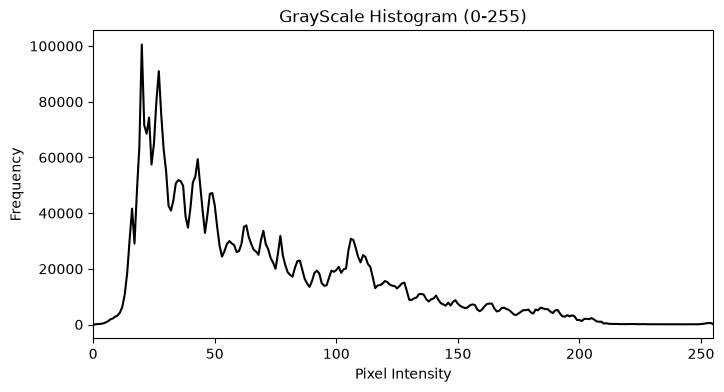

In [ ]:
hist=cv.calcHist([img],[0],None,[256],[0,256])

plt.figure(figsize=(8,4))
plt.plot(hist,color='black')
plt.title("GrayScale Histogram (0-255)")
plt.xlabel('Pixel Intensity')
plt.ylabel("Frequency")
plt.xlim([0,255])
plt.show()

### Global Histogram Equiliztion

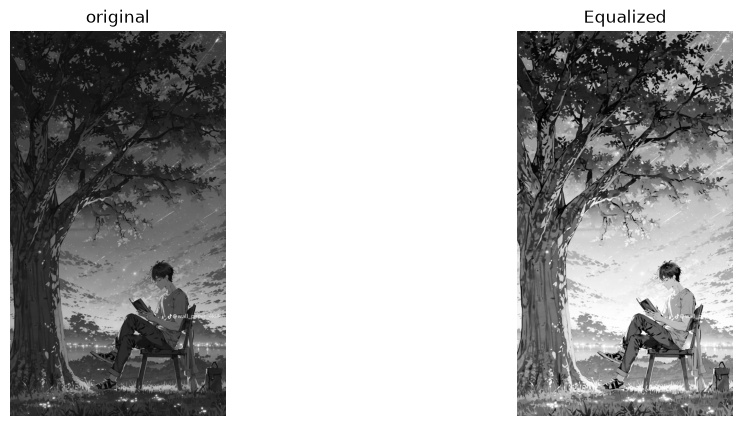

In [25]:
equalized_img=cv.equalizeHist(img)

fig,axs=plt.subplots(1,2,figsize=(12,5))
axs[0].imshow(img,cmap='gray',vmin=0,vmax=255);axs[0].set_title("original")
axs[1].imshow(equalized_img,cmap='gray',vmin=0,vmax=255);axs[1].set_title("Equalized")
for ax in axs:ax.axis('off')
plt.show()

### CLAHE

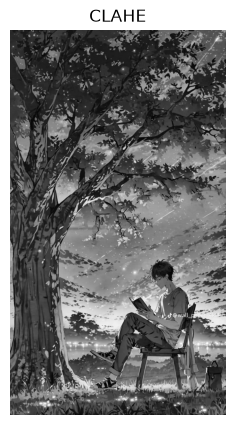

In [ ]:
clahe=cv.createCLAHE(clipLimit=2.0,tileGridSize=(8,8))
clahe_img=clahe.apply(img)
plt.figure(figsize=(5,5))
plt.imshow(clahe_img,cmap='gray',vmin=0,vmax=255)
plt.title("CLAHE")
plt.axis('off')
plt.show()

## Fixed Binary Threstholding

Unique values in fixed Thresthold: [  0 255]


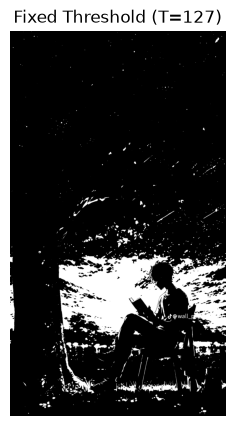

In [22]:
ret_fixed,thresh_fixed=cv.threshold(img,127,255,cv.THRESH_BINARY)

print(f"Unique values in fixed Thresthold: {np.unique(thresh_fixed)}")

plt.figure(figsize=(5,5))
plt.imshow(thresh_fixed,cmap='gray',vmin=0,vmax=255)
plt.title("Fixed Threshold (T=127)")
plt.axis('off')
plt.show()

### OTSU Threstholding

otsu calculate Threshold: 83.0


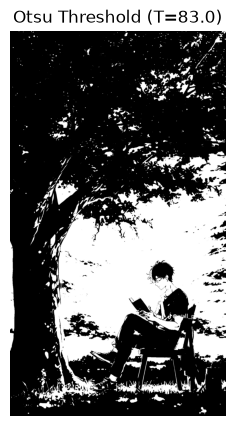

In [ ]:
ret_otsu,threst_otsu=cv.threshold(img,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)
print(f"otsu calculate Threshold: {ret_otsu}")
plt.figure(figsize=(5,5))
plt.imshow(threst_otsu,cmap='gray',vmin=0,vmax=255)
plt.title(f"Otsu Threshold (T={ret_otsu})")
plt.axis('off')

plt.show()

### Adaptive Gaussian Thresholding

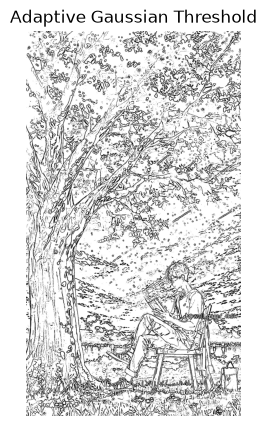

In [ ]:
adaptive_img=cv.adaptiveThreshold(img,255,cv.ADAPTIVE_THRESH_GAUSSIAN_C,cv.THRESH_BINARY,11,2)
plt.figure(figsize=(5,5))
plt.imshow(adaptive_img,cmap='gray',vmin=0,vmax=255)
plt.title("Adaptive Gaussian Threshold")
plt.axis('off')
plt.show()